# imports

In [1]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import pandas as pd
import numpy as np

# folder and files

In [2]:
base_path = Path(r"F:\عریشیاس\ml\mining")

train_path = base_path / "train"

print("Train folder exists:", train_path.exists())
print("Train folder path:", train_path)

images = list(train_path.rglob("*.jpg"))

print("Number of images:", len(images))

Train folder exists: True
Train folder path: F:\عریشیاس\ml\mining\train
Number of images: 156


# Unique boreholes

In [3]:
boreholes = set()

for image in images:
    parts = image.stem.split("-")

    mine_id = parts[0]
    borehole_id = parts[1]

    boreholes.add((mine_id, borehole_id))

print("Unique boreholes:")
for borehole in sorted(boreholes):
    print(borehole)

print("Total:", len(boreholes))

Unique boreholes:
('M3', 'BH130')
('M3', 'BH13150')
('M3', 'BH13250')
('M3', 'BH13400')
('M3', 'BH300')
Total: 5


# Read the Excel file

In [4]:
excel_path = base_path / "from-to-rqd.xlsx"

df = pd.read_excel(excel_path)

print(df.columns)
df.head()

Index(['RunId', 'from', 'to'], dtype='str')


,RunId,from,to
0,M3-BH3299-1-1,0.0,2.2
1,M3-BH3299-1-2,2.2,3.3
2,M3-BH3299-1-3,3.3,4.4
3,M3-BH3299-2-1,4.4,4.9
4,M3-BH3299-2-2,4.9,6.5


# Max Run

In [5]:
df["Run_Length"] = df["to"] - df["from"]

max_run_length = df["Run_Length"].max()

print("Maximum Run Length:", max_run_length)
print("Integer part:", int(max_run_length))

Maximum Run Length: 3.1000000000000085
Integer part: 3


# longest to

In [6]:
max_index = df["to"].idxmax()

deepest_run = df.loc[max_index]

print(deepest_run)

RunId         M3-BH3301-21-1
from                    94.7
to                     95.65
Run_Length              0.95
Name: 179, dtype: object


# Text file for answers

In [7]:
answers = [
    156,
    5,
    3,
    "M3-BH3301"
]

output_path = base_path / "output.txt"

output_path.write_text(
    "\n".join(map(str, answers)),
    encoding="utf-8"
)

print("Output file created:", output_path)

Output file created: F:\عریشیاس\ml\mining\output.txt


In [6]:
! gdown --id 1fSzUMCJHx3JHwrDpY_Qz6KI1zIUv3BnC

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1fSzUMCJHx3JHwrDpY_Qz6KI1zIUv3BnC
From (redirected): https://drive.google.com/uc?id=1fSzUMCJHx3JHwrDpY_Qz6KI1zIUv3BnC&confirm=t&uuid=0d0070b1-f485-4c6d-92fa-8b519a81cf44
To: /content/data.zip
100% 1.45G/1.45G [00:18<00:00, 77.9MB/s]


In [7]:
!ls -lh

total 1.4G
-rw-r--r-- 1 root root 1.4G Aug 22  2021 data.zip
drwxr-xr-x 1 root root 4.0K Nov  4 17:01 sample_data


In [8]:
!unzip data.zip -d data

Archive:  data.zip
  inflating: data/from-to-rqd.xlsx   
  inflating: data/label.xlsx         
   creating: data/test-rqd/
  inflating: data/test-rqd/M3-BH3299-1.jpg  
  inflating: data/test-rqd/M3-BH3299-2.jpg  
  inflating: data/test-rqd/M3-BH3299-3.jpg  
  inflating: data/test-rqd/M3-BH3299-4.jpg  
  inflating: data/test-rqd/M3-BH3299-5.jpg  
  inflating: data/test-rqd/M3-BH3299-6.jpg  
  inflating: data/test-rqd/M3-BH3299-7.jpg  
  inflating: data/test-rqd/M3-BH3299-8.jpg  
  inflating: data/test-rqd/M3-BH3299-9.jpg  
  inflating: data/test-rqd/M3-BH3300-1.jpg  
  inflating: data/test-rqd/M3-BH3300-10.jpg  
  inflating: data/test-rqd/M3-BH3300-11.jpg  
  inflating: data/test-rqd/M3-BH3300-12.jpg  
  inflating: data/test-rqd/M3-BH3300-13.jpg  
  inflating: data/test-rqd/M3-BH3300-14.jpg  
  inflating: data/test-rqd/M3-BH3300-15.jpg  
  inflating: data/test-rqd/M3-BH3300-16.jpg  
  inflating: data/test-rqd/M3-BH3300-17.jpg  
  inflating: data/test-rqd/M3-BH3300-18.jpg  
  inflating: 

In [9]:
!ls data

from-to-rqd.xlsx  label.xlsx  test-rqd	train


In [10]:
import os
import shutil
import yaml
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from sklearn.model_selection import train_test_split
from PIL import Image

In [11]:
DATA_PATH = "/content/data"

print(os.listdir(DATA_PATH))

['test-rqd', 'label.xlsx', 'from-to-rqd.xlsx', 'train']


In [12]:
from_to = pd.read_excel(f"{DATA_PATH}/from-to-rqd.xlsx")
labels = pd.read_excel(f"{DATA_PATH}/label.xlsx")

print("FROM-TO:")
display(from_to.head())

print("LABELS:")
display(labels.head())

print("TRAIN FILES:")
print(os.listdir(f"{DATA_PATH}/train")[:10])

print("TEST FILES:")
print(os.listdir(f"{DATA_PATH}/test-rqd")[:10])

FROM-TO:


,RunId,from,to
0,M3-BH3299-1-1,0.0,2.2
1,M3-BH3299-1-2,2.2,3.3
2,M3-BH3299-1-3,3.3,4.4
3,M3-BH3299-2-1,4.4,4.9
4,M3-BH3299-2-2,4.9,6.5


LABELS:


,image_name,label_name,xmin,ymin,width,height,image_width,image_height
0,M3-BH130-1.jpg,wood,2412,1552,152,197,4020,2929
1,M3-BH130-1.jpg,wood,2917,2072,140,220,4020,2929
2,M3-BH130-1.jpg,wood,3820,1567,167,209,4020,2929
3,M3-BH130-1.jpg,wood,3603,2341,201,186,4020,2929
4,M3-BH130-1.jpg,wood,1676,2713,159,171,4020,2929


TRAIN FILES:
['M3-BH13150-6.jpg', 'M3-BH13150-34.jpg', 'M3-BH13250-19.jpg', 'M3-BH13150-33.jpg', 'M3-BH300-42.JPG', 'M3-BH300-30.JPG', 'M3-BH13150-8.jpg', 'M3-BH13250-4.jpg', 'M3-BH13250-30.jpg', 'M3-BH300-39.JPG']
TEST FILES:
['M3-BH3300-12.jpg', 'M3-BH3300-14.jpg', 'M3-BH3300-11.jpg', 'M3-BH3300-8.jpg', 'M3-BH3300-18.jpg', 'M3-BH3299-2.jpg', 'M3-BH3301-16.jpg', 'M3-BH3301-18.jpg', 'M3-BH3301-17.jpg', 'M3-BH3300-5.jpg']


In [13]:
labels = pd.read_excel("/content/data/label.xlsx")
runs = pd.read_excel("/content/data/from-to-rqd.xlsx")

print("LABEL CLASSES:")
print(labels["label_name"].value_counts())

print("\nNUMBER OF ANNOTATED IMAGES:")
print(labels["image_name"].nunique())

print("\nNUMBER OF TRAIN IMAGES:")
print(len(os.listdir("/content/data/train")))

print("\nNUMBER OF TEST IMAGES:")
print(len(os.listdir("/content/data/test-rqd")))

print("\nRUNS:")
print(len(runs))

print("\nSAMPLE RUNS:")
display(runs.head(10))

LABEL CLASSES:
label_name
+10cm rock    1946
wood           417
Name: count, dtype: int64

NUMBER OF ANNOTATED IMAGES:
156

NUMBER OF TRAIN IMAGES:
156

NUMBER OF TEST IMAGES:
48

RUNS:
180

SAMPLE RUNS:


,RunId,from,to
0,M3-BH3299-1-1,0.0,2.2
1,M3-BH3299-1-2,2.2,3.3
2,M3-BH3299-1-3,3.3,4.4
3,M3-BH3299-2-1,4.4,4.9
4,M3-BH3299-2-2,4.9,6.5
5,M3-BH3299-2-3,6.5,7.7
6,M3-BH3299-2-4,7.7,10.0
7,M3-BH3299-2-5,10.0,10.7
8,M3-BH3299-2-6,10.7,11.4
9,M3-BH3299-3-1,11.4,11.6


Test image: M3-BH3300-12.jpg
Image size: (3603, 2979)


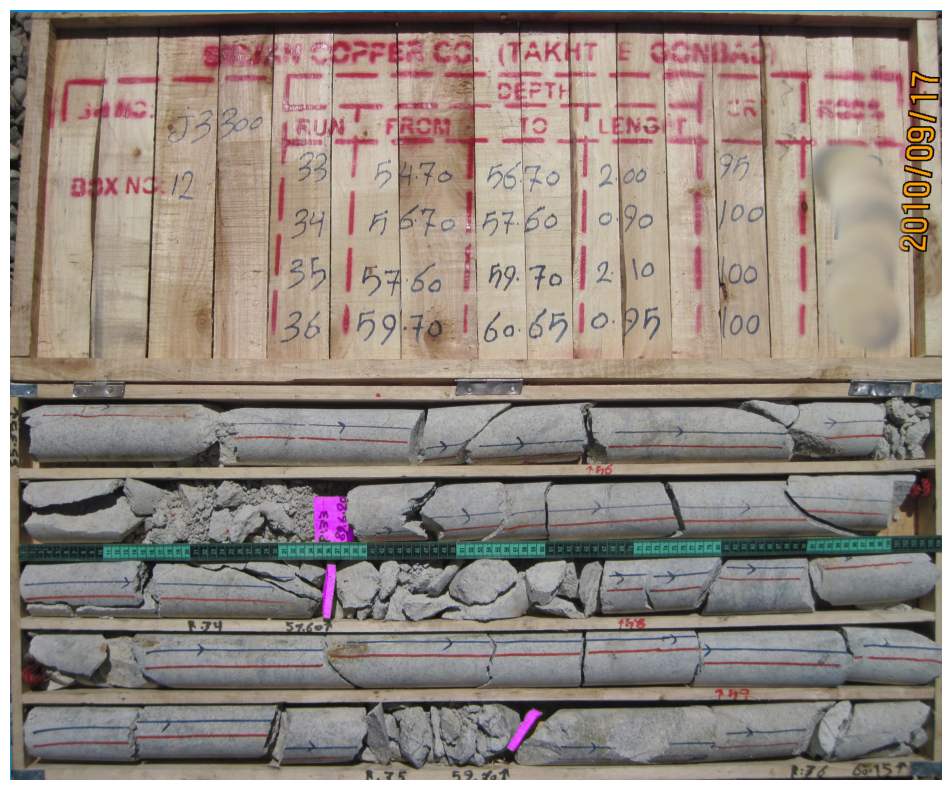

In [14]:
img_name = os.listdir("/content/data/test-rqd")[0]
img = Image.open(f"/content/data/test-rqd/{img_name}")

print("Test image:", img_name)
print("Image size:", img.size)

plt.figure(figsize=(16, 10))
plt.imshow(img)
plt.axis("off");
plt.show()

In [15]:
print("RUNS FOR BH3301-9:")
display(
    runs[runs["RunId"].str.contains("BH3301-9", na=False)]
)

print("\nSAMPLE ANNOTATIONS:")
display(
    labels[labels["image_name"] == "M3-BH130-1.jpg"].head(10)
)

print("\nIMAGE DIMENSIONS:")
print(img.size)

RUNS FOR BH3301-9:


,RunId,from,to
137,M3-BH3301-9-1,36.25,38.3
138,M3-BH3301-9-2,38.30,39.8
139,M3-BH3301-9-3,39.80,41.0



SAMPLE ANNOTATIONS:


,image_name,label_name,xmin,ymin,width,height,image_width,image_height
0,M3-BH130-1.jpg,wood,2412,1552,152,197,4020,2929
1,M3-BH130-1.jpg,wood,2917,2072,140,220,4020,2929
2,M3-BH130-1.jpg,wood,3820,1567,167,209,4020,2929
3,M3-BH130-1.jpg,wood,3603,2341,201,186,4020,2929
4,M3-BH130-1.jpg,wood,1676,2713,159,171,4020,2929
5,M3-BH130-1.jpg,+10cm rock,94,1563,307,209,4020,2929
6,M3-BH130-1.jpg,+10cm rock,439,1559,330,209,4020,2929
7,M3-BH130-1.jpg,+10cm rock,398,1836,288,182,4020,2929
8,M3-BH130-1.jpg,+10cm rock,936,1833,433,197,4020,2929
9,M3-BH130-1.jpg,+10cm rock,1399,1825,285,197,4020,2929



IMAGE DIMENSIONS:
(3603, 2979)


In [16]:


DATA = "/content/data"
OUT = "/content/yolo_dataset"

labels = pd.read_excel(f"{DATA}/label.xlsx")

classes = {
    "+10cm rock": 0,
    "wood": 1
}

if os.path.exists(OUT):
    shutil.rmtree(OUT)

for split in ["train", "val"]:
    os.makedirs(f"{OUT}/images/{split}", exist_ok=True)
    os.makedirs(f"{OUT}/labels/{split}", exist_ok=True)

images = sorted(os.listdir(f"{DATA}/train"))
train_images, val_images = train_test_split(
    images, test_size=0.2, random_state=42
)

for split, image_list in [
    ("train", train_images),
    ("val", val_images)
]:
    for image_name in image_list:
        src = f"{DATA}/train/{image_name}"
        dst = f"{OUT}/images/{split}/{image_name}"
        shutil.copy2(src, dst)

        image_labels = labels[
            labels["image_name"].str.lower() == image_name.lower()
        ]

        lines = []

        for _, row in image_labels.iterrows():
            cls = classes[row["label_name"]]

            x = (row["xmin"] + row["width"] / 2) / row["image_width"]
            y = (row["ymin"] + row["height"] / 2) / row["image_height"]
            w = row["width"] / row["image_width"]
            h = row["height"] / row["image_height"]

            lines.append(f"{cls} {x} {y} {w} {h}")

        with open(
            f"{OUT}/labels/{split}/{os.path.splitext(image_name)[0]}.txt",
            "w"
        ) as f:
            f.write("\n".join(lines))

config = {
    "path": OUT,
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "+10cm rock",
        1: "wood"
    }
}

with open(f"{OUT}/data.yaml", "w") as f:
    yaml.safe_dump(config, f)

print("YOLO dataset prepared.")
print("GPU available:", torch.cuda.is_available())

YOLO dataset prepared.
GPU available: True


In [17]:
!pip install -q ultralytics

In [18]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=f"{OUT}/data.yaml",
    epochs=60,
    imgsz=960,
    batch=4,
    patience=12,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    project="/content/results",
    name="rqd_model"
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rqd_model, nbs=64, nms=None, opset=None, optimize=False, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ade33821c50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [19]:
model = YOLO("/content/results/rqd_model/weights/best.pt")

results = model.predict(
    source="/content/data/test-rqd",
    imgsz=960,
    conf=0.25,
    save=True,
    save_txt=True,
    device=0
)

print("Images processed:", len(results))
print("Predictions saved.")


image 1/48 /content/data/test-rqd/M3-BH3299-1.jpg: 800x960 9 +10cm rocks, 3 woods, 23.3ms
image 2/48 /content/data/test-rqd/M3-BH3299-2.jpg: 800x960 11 +10cm rocks, 6 woods, 23.4ms
image 3/48 /content/data/test-rqd/M3-BH3299-3.jpg: 736x960 1 +10cm rock, 5 woods, 94.6ms
image 4/48 /content/data/test-rqd/M3-BH3299-4.jpg: 736x960 6 +10cm rocks, 3 woods, 26.9ms
image 5/48 /content/data/test-rqd/M3-BH3299-5.jpg: 768x960 4 +10cm rocks, 4 woods, 97.1ms
image 6/48 /content/data/test-rqd/M3-BH3299-6.jpg: 800x960 3 woods, 24.7ms
image 7/48 /content/data/test-rqd/M3-BH3299-7.jpg: 704x960 3 +10cm rocks, 4 woods, 65.7ms
image 8/48 /content/data/test-rqd/M3-BH3299-8.jpg: 864x960 4 +10cm rocks, 4 woods, 92.9ms
image 9/48 /content/data/test-rqd/M3-BH3299-9.jpg: 736x960 21 +10cm rocks, 3 woods, 26.1ms
image 10/48 /content/data/test-rqd/M3-BH3300-1.jpg: 800x960 10 +10cm rocks, 2 woods, 24.6ms
image 11/48 /content/data/test-rqd/M3-BH3300-10.jpg: 800x960 12 +10cm rocks, 1 wood, 23.3ms
image 12/48 /conten

In [20]:
import os
import pandas as pd

runs = pd.read_excel("/content/data/from-to-rqd.xlsx")
pred_dir = "/content/runs/detect/predict/labels"

# M3-BH3299-1-1  →  M3-BH3299-1.txt
runs["image_base"] = runs["RunId"].astype(str).apply(
    lambda x: "-".join(x.split("-")[:3])
)

for image_base, group in runs.groupby("image_base"):
    filename = image_base + ".txt"
    path = os.path.join(pred_dir, filename)

    rocks = 0
    woods = 0

    if os.path.exists(path):
        with open(path, "r") as f:
            for line in f:
                cls = int(line.split()[0])

                if cls == 0:
                    rocks += 1
                elif cls == 1:
                    woods += 1

    print(
        filename,
        "Runs:", len(group),
        "Rocks:", rocks,
        "Woods:", woods
    )

M3-BH3299-1.txt Runs: 3 Rocks: 9 Woods: 3
M3-BH3299-2.txt Runs: 6 Rocks: 11 Woods: 6
M3-BH3299-3.txt Runs: 5 Rocks: 1 Woods: 5
M3-BH3299-4.txt Runs: 4 Rocks: 6 Woods: 3
M3-BH3299-5.txt Runs: 4 Rocks: 4 Woods: 4
M3-BH3299-6.txt Runs: 3 Rocks: 0 Woods: 3
M3-BH3299-7.txt Runs: 5 Rocks: 3 Woods: 4
M3-BH3299-8.txt Runs: 5 Rocks: 4 Woods: 4
M3-BH3299-9.txt Runs: 3 Rocks: 21 Woods: 3
M3-BH3300-1.txt Runs: 3 Rocks: 10 Woods: 2
M3-BH3300-10.txt Runs: 2 Rocks: 12 Woods: 1
M3-BH3300-11.txt Runs: 3 Rocks: 20 Woods: 4
M3-BH3300-12.txt Runs: 4 Rocks: 24 Woods: 3
M3-BH3300-13.txt Runs: 3 Rocks: 17 Woods: 4
M3-BH3300-14.txt Runs: 4 Rocks: 21 Woods: 4
M3-BH3300-15.txt Runs: 4 Rocks: 21 Woods: 4
M3-BH3300-16.txt Runs: 4 Rocks: 16 Woods: 4
M3-BH3300-17.txt Runs: 3 Rocks: 19 Woods: 2
M3-BH3300-18.txt Runs: 2 Rocks: 11 Woods: 3
M3-BH3300-2.txt Runs: 3 Rocks: 19 Woods: 2
M3-BH3300-3.txt Runs: 5 Rocks: 8 Woods: 5
M3-BH3300-4.txt Runs: 5 Rocks: 11 Woods: 4
M3-BH3300-5.txt Runs: 4 Rocks: 27 Woods: 4
M3-BH3300-

In [21]:
DATA = '/content/data'
TEST_DIR = Path(DATA) / 'test-rqd'
BEST_WEIGHTS = '/content/results/rqd_model/weights/best.pt'
CONFIDENCE = 0.20
IMAGE_WIDTH_METERS = 1.1

model = YOLO(BEST_WEIGHTS)
test_paths = sorted(p for p in TEST_DIR.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
test_results = {}

for image_path in test_paths:
    prediction = model.predict(
        source=str(image_path), imgsz=960, conf=CONFIDENCE,
        device=0 if torch.cuda.is_available() else 'cpu', verbose=False
    )[0]
    test_results[image_path.stem] = prediction

print(f'{len(test_results)} test image processed.')

48 test image processed.


In [22]:
def result_to_boxes(result, confidence=CONFIDENCE):
    if result.boxes is None or len(result.boxes) == 0:
        return []
    boxes = []
    for xyxy, cls, conf in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.cls.cpu().numpy(),
        result.boxes.conf.cpu().numpy(),
    ):
        if conf < confidence:
            continue
        x1, y1, x2, y2 = map(float, xyxy)
        boxes.append({
            'class_id': int(cls),
            'x1': x1, 'x2': x2,
            'cy': (y1 + y2) / 2,
            'height': y2 - y1,
        })
    return boxes

def cluster_rows(boxes, image_height):
    if not boxes:
        return []
    boxes = sorted(boxes, key=lambda box: box['cy'])
    median_box_height = np.median([box['height'] for box in boxes])
    row_gap = max(0.60 * median_box_height, 0.035 * image_height)
    rows = [[boxes[0]]]
    for box in boxes[1:]:
        if box['cy'] - rows[-1][-1]['cy'] > row_gap:
            rows.append([box])
        else:
            rows[-1].append(box)
    return rows

def rqd_to_group(rqd_percent):
    if rqd_percent <= 25: return 1
    if rqd_percent < 50: return 2
    if rqd_percent < 75: return 3
    if rqd_percent < 90: return 4
    return 5

In [23]:
def calculate_image_predictions(result, image_path, image_runs):
    image_width, image_height = Image.open(image_path).size
    rows = cluster_rows(result_to_boxes(result), image_height)
    if not rows:
        return [1] * len(image_runs)

    rocks, woods = [], []
    for row_number, row in enumerate(rows):
        for box in row:
            left = row_number * image_width + box['x1']
            right = row_number * image_width + box['x2']
            if box['class_id'] == 0:       # +10cm rock
                rocks.append((left, right))
            elif box['class_id'] == 1:     # wood
                woods.append((left + right) / 2)

    run_lengths = (image_runs['to'] - image_runs['from']).astype(float).tolist()
    expected_boundaries = [0.0]
    for run_length in run_lengths:
        expected_boundaries.append(
            expected_boundaries[-1] + run_length / IMAGE_WIDTH_METERS * image_width
        )
    expected_boundaries[-1] = len(rows) * image_width

    woods = sorted(woods)
    available_woods = set(range(len(woods)))
    boundaries = expected_boundaries.copy()
    for boundary_index in range(1, len(boundaries) - 1):
        nearby = [
            wood_index for wood_index in available_woods
            if abs(woods[wood_index] - boundaries[boundary_index]) <= 0.18 * image_width
        ]
        if nearby:
            closest = min(nearby, key=lambda i: abs(woods[i] - boundaries[boundary_index]))
            boundaries[boundary_index] = woods[closest]
            available_woods.remove(closest)

    predictions = []
    for run_index, run_length in enumerate(run_lengths):
        left, right = boundaries[run_index], boundaries[run_index + 1]
        rock_length_m = sum(
            max(0.0, min(right, rock_right) - max(left, rock_left))
            / image_width * IMAGE_WIDTH_METERS
            for rock_left, rock_right in rocks
        )
        rqd = min(100.0, 100 * rock_length_m / run_length) if run_length > 0 else 0.0
        predictions.append(rqd_to_group(rqd))
    return predictions

In [27]:
runs_rqd = pd.read_excel(f'{DATA}/from-to-rqd.xlsx')
runs_rqd.columns = [column.lower() for column in runs_rqd.columns]
runs_rqd = runs_rqd.rename(columns={'runid': 'RunId'})
runs_rqd['image_stem'] = runs_rqd['RunId'].map(lambda run_id: run_id.rsplit('-', 1)[0])
runs_rqd['run_number'] = runs_rqd['RunId'].map(lambda run_id: int(run_id.rsplit('-', 1)[1]))

output_rows = []
for image_stem, image_runs in runs_rqd.groupby('image_stem', sort=False):
    image_runs = image_runs.sort_values('run_number').reset_index(drop=True)
    if image_stem not in test_results:
        raise FileNotFoundError(f'برای {image_stem} تصویر آزمون پیدا نشد.')
    image_path = next(path for path in test_paths if path.stem == image_stem)
    prediction_groups = calculate_image_predictions(
        test_results[image_stem], image_path, image_runs
    )
    output_rows.extend(
        {'RunId': run_id, 'Prediction': prediction}
        for run_id, prediction in zip(image_runs['RunId'], prediction_groups)
    )

output = pd.DataFrame(output_rows)
output = output.sort_values('RunId').reset_index(drop=True)
output.to_csv('/content/output.csv', index=False)
display(output.head(10))
print('file created:', '/content/output.csv')
print('number of runs:', len(output))

,RunId,Prediction
0,M3-BH3299-1-1,2
1,M3-BH3299-1-2,3
2,M3-BH3299-1-3,3
3,M3-BH3299-2-1,2
4,M3-BH3299-2-2,1
5,M3-BH3299-2-3,4
6,M3-BH3299-2-4,1
7,M3-BH3299-2-5,1
8,M3-BH3299-2-6,1
9,M3-BH3299-3-1,3


file created: /content/output.csv
number of runs: 180


In [26]:
assert output.columns.tolist() == ['RunId', 'Prediction']
assert len(output) == len(runs_rqd)
assert output['RunId'].is_unique
assert output['Prediction'].isin([1, 2, 3, 4, 5]).all()
print('correct')

from google.colab import files
files.download('/content/output.csv')

correct


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>